# Task A1: Breast Cancer Diagnosis from Cell-Nucleus Measurements

| Field | Detail |
|---|---|
| **Student** | Muhammad Ahmad |
| **SAP ID** | 70177776 |
| **Section** | BSRAI-C |
| **Course** | AI-101 Introduction to Artificial Intelligence |
| **University** | The University of Lahore |

---

## Objective
Build and compare classifiers that distinguish **malignant** (class 0) from **benign** (class 1) breast tumours using 30 cell-nucleus measurements extracted from fine-needle aspirate images.

**Primary metrics**: Recall and F1-score on the malignant class (since missing a malignant tumour is far costlier than a false alarm).

## Notebook Outline
1. Setup & Imports
2. Data Loading & Exploration (EDA)
3. Preprocessing & Train/Test Split
4. Model Training & Hyperparameter Tuning
5. Test-Set Evaluation & Comparison
6. Threshold Study (Recall ≥ 0.95)
7. Feature Importance Analysis
8. Dropping Correlated Features Experiment
9. Conclusions

---
## 1. Setup & Imports

In [1]:
# ── Standard library & utilities ──────────────────────────────────────────────
import warnings, os, pathlib
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── Scikit-learn ──────────────────────────────────────────────────────────────
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
    cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, precision_recall_curve
)

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Figure output directory ──────────────────────────────────────────────────
FIG_DIR = pathlib.Path('figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Plot style ───────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Setup complete ✓')

Setup complete ✓


---
## 2. Data Loading & Exploratory Data Analysis (EDA)

In [2]:
# Load the built-in breast cancer dataset
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target                       # 0 = malignant, 1 = benign
df['diagnosis'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

print(f'Dataset shape: {df.shape}')
print(f'Features: {cancer.feature_names.tolist()}')
print(f'\nTarget names: {cancer.target_names.tolist()}')
print(f'  0 → {cancer.target_names[0]}  |  1 → {cancer.target_names[1]}')
df.head()

Dataset shape: (569, 32)
Features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target names: ['malignant', 'benign']
  0 → malignant  |  1 → benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


### 2.1 Class Distribution

Class distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64

Malignant proportion: 37.26%
Benign proportion:    62.74%


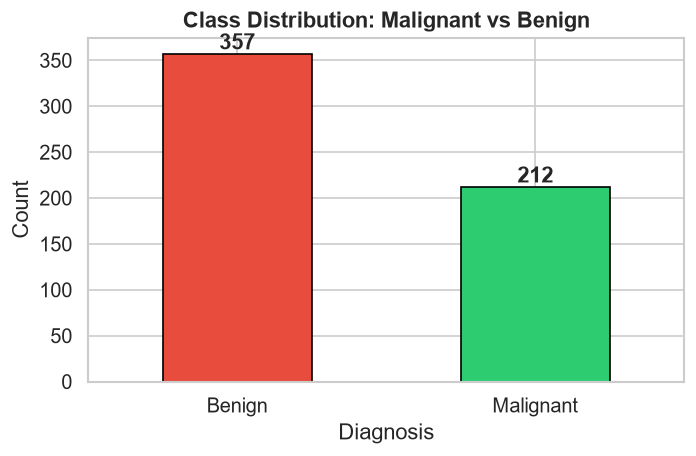

In [3]:
class_counts = df['diagnosis'].value_counts()
print('Class distribution:')
print(class_counts)
print(f'\nMalignant proportion: {(df["target"] == 0).mean():.2%}')
print(f'Benign proportion:    {(df["target"] == 1).mean():.2%}')

fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#e74c3c', '#2ecc71']
class_counts.plot(kind='bar', color=colors, edgecolor='black', ax=ax)
ax.set_title('Class Distribution: Malignant vs Benign', fontweight='bold')
ax.set_xlabel('Diagnosis')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for i, v in enumerate(class_counts):
    ax.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
fig.savefig(FIG_DIR / 'class_distribution.png', bbox_inches='tight')
plt.show()

### 2.2 Summary Statistics

In [4]:
# Summary statistics for all 30 features
summary = df.drop(columns=['target', 'diagnosis']).describe().T
summary['missing'] = df.drop(columns=['target', 'diagnosis']).isnull().sum()
print('Summary Statistics (all 30 features):')
summary.round(3)

Summary Statistics (all 30 features):


,count,mean,std,min,25%,50%,75%,max,missing
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110,0
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280,0
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500,0
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000,0
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163,0
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345,0
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427,0
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201,0
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304,0
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097,0


In [5]:
# Summary statistics grouped by diagnosis
print('\nMean values by class (first 10 features shown):')
grouped = df.drop(columns=['diagnosis']).groupby('target').mean().T
grouped.columns = ['Malignant (0)', 'Benign (1)']
grouped['Diff (M-B)'] = grouped['Malignant (0)'] - grouped['Benign (1)']
grouped.round(3).head(10)


Mean values by class (first 10 features shown):


,Malignant (0),Benign (1),Diff (M-B)
mean radius,17.463,12.147,5.316
mean texture,21.605,17.915,3.690
mean perimeter,115.365,78.075,37.290
mean area,978.376,462.790,515.586
mean smoothness,0.103,0.092,0.010
mean compactness,0.145,0.080,0.065
mean concavity,0.161,0.046,0.115
mean concave points,0.088,0.026,0.062
mean symmetry,0.193,0.174,0.019
mean fractal dimension,0.063,0.063,-0.000


### 2.3 Correlation Heatmap & Feature Groups

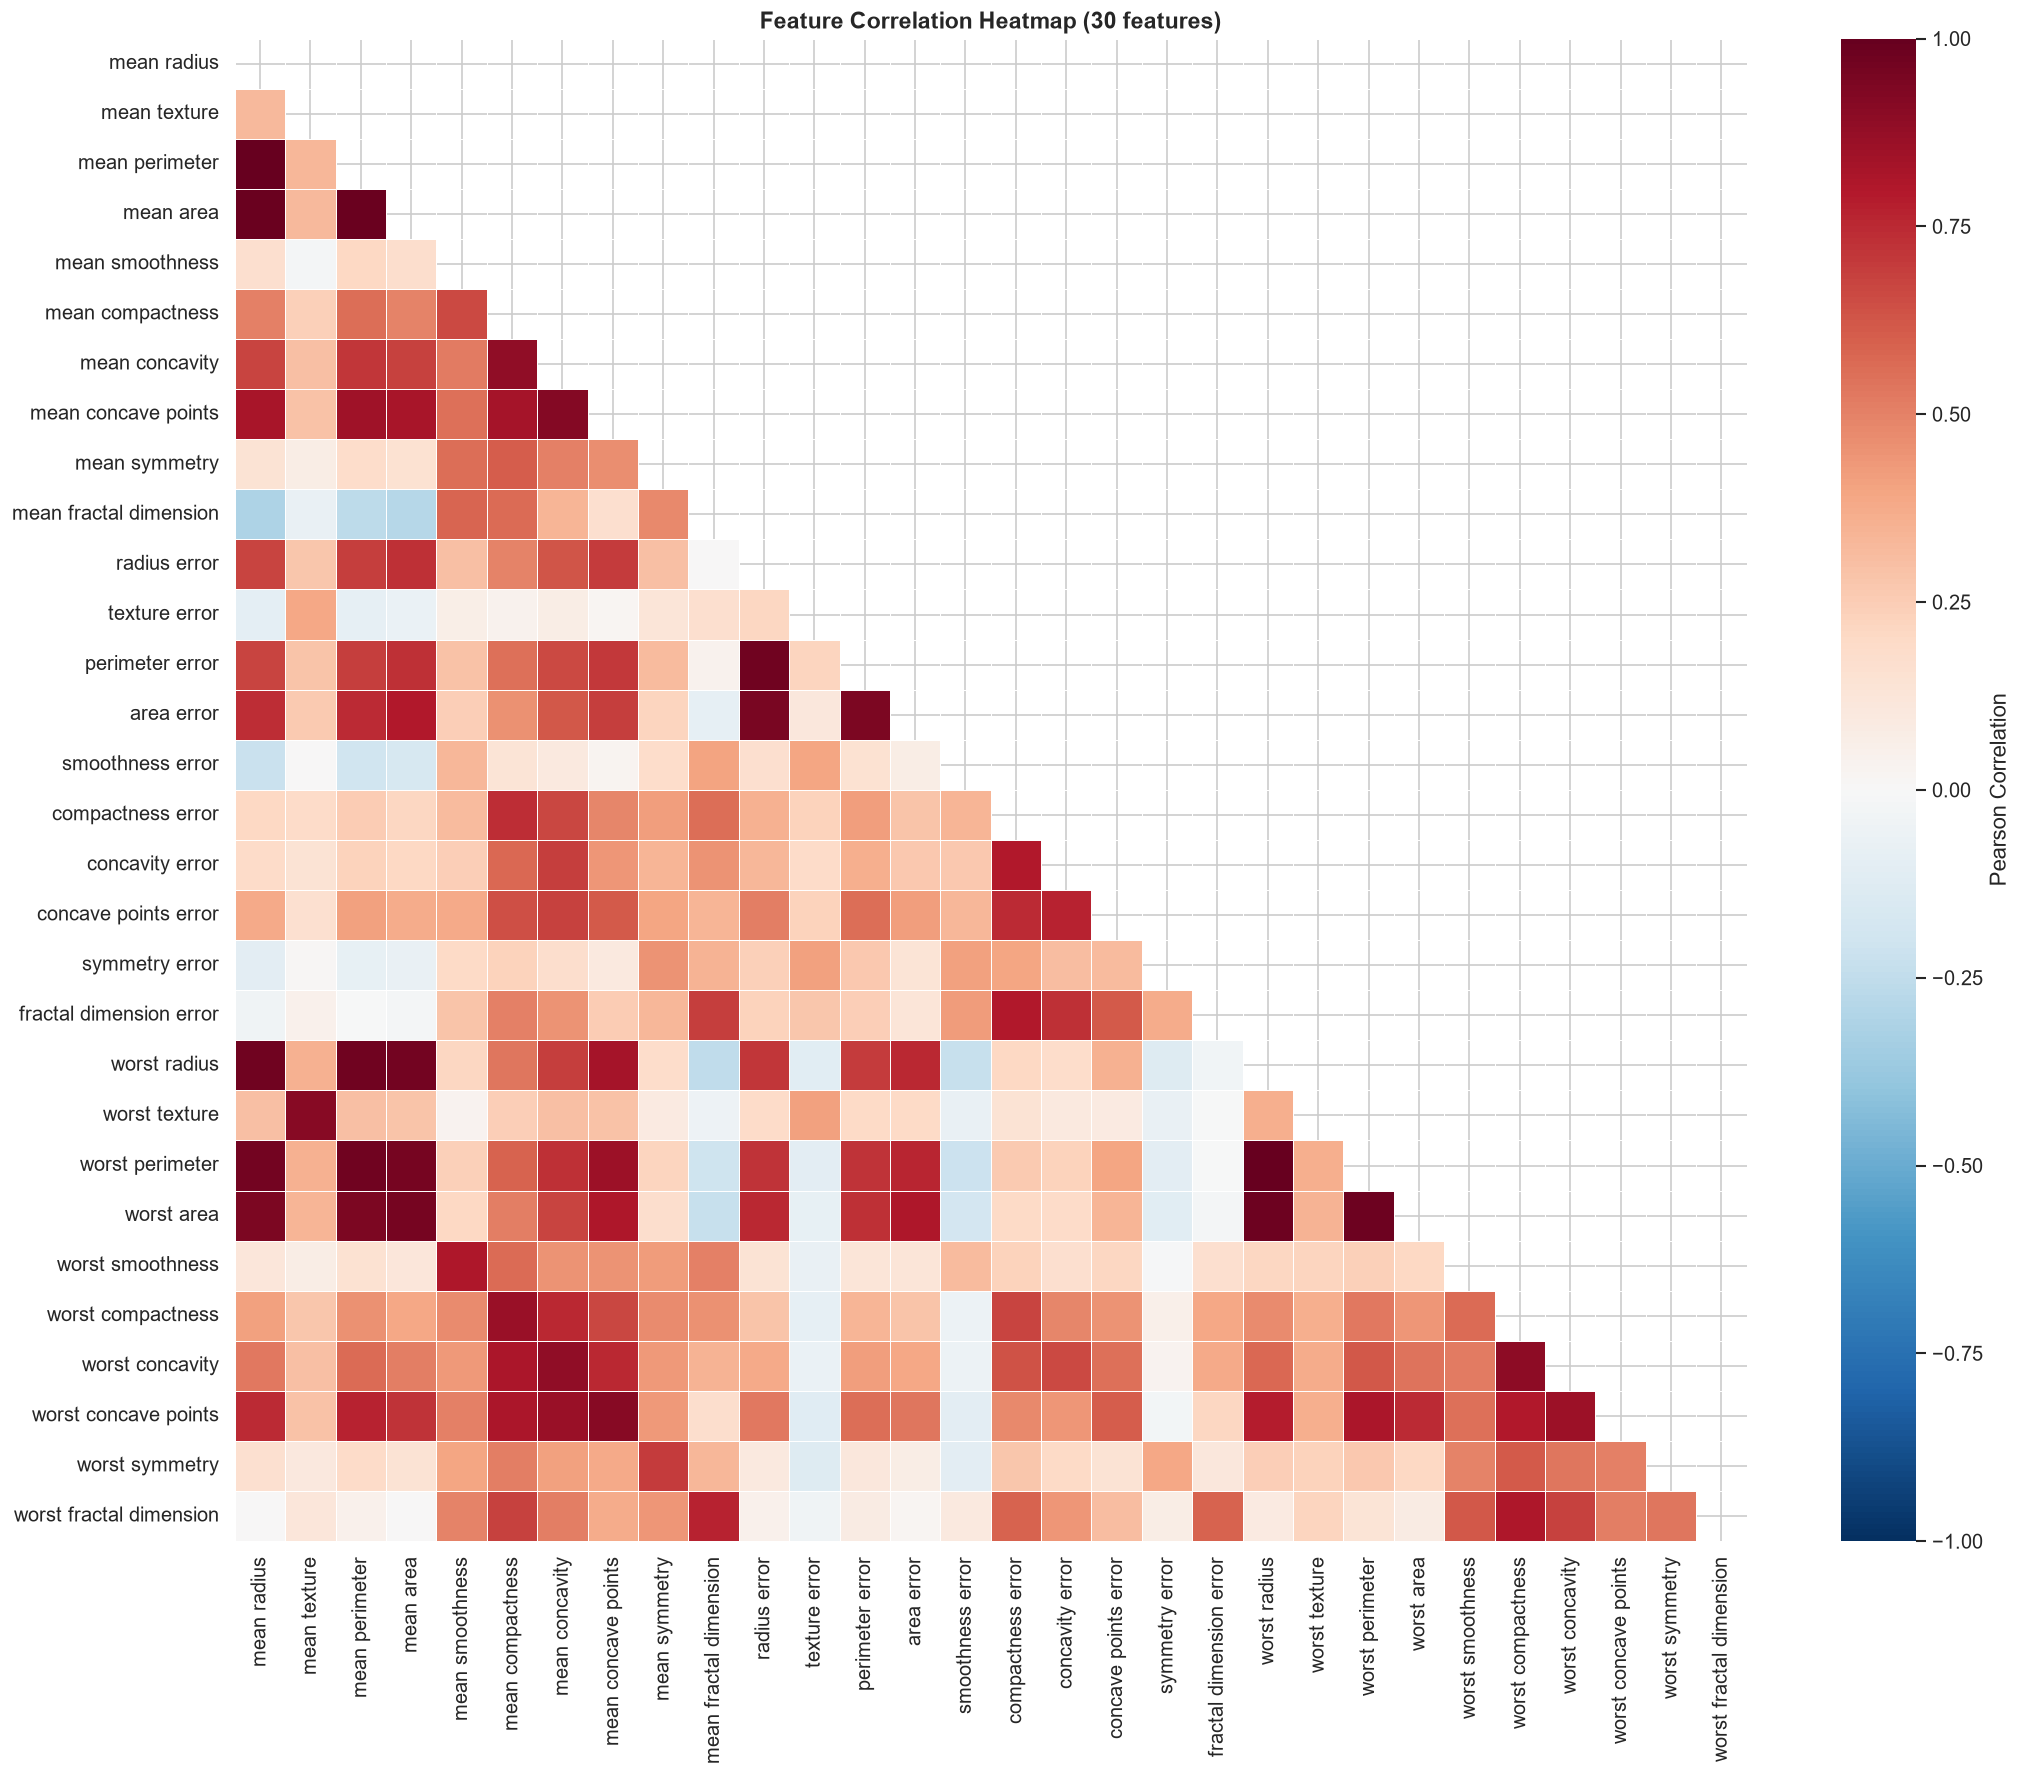

In [6]:
# Full correlation heatmap
corr = df.drop(columns=['target', 'diagnosis']).corr()

fig, ax = plt.subplots(figsize=(18, 15))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=False, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Pearson Correlation'})
ax.set_title('Feature Correlation Heatmap (30 features)', fontweight='bold', fontsize=14)
plt.tight_layout()
fig.savefig(FIG_DIR / 'correlation_heatmap.png', bbox_inches='tight')
plt.show()

In [7]:
# Identify groups of strongly correlated features (|r| > 0.90)
high_corr_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]
        if abs(r) > 0.90:
            high_corr_pairs.append((corr.columns[i], corr.columns[j], round(r, 3)))

high_corr_df = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])
high_corr_df = high_corr_df.sort_values('Correlation', ascending=False, key=abs)
print(f'Feature pairs with |correlation| > 0.90  ({len(high_corr_df)} pairs):')
high_corr_df.reset_index(drop=True)

Feature pairs with |correlation| > 0.90  (21 pairs):


,Feature 1,Feature 2,Correlation
0,mean radius,mean perimeter,0.998
1,worst radius,worst perimeter,0.994
2,mean radius,mean area,0.987
3,mean perimeter,mean area,0.987
4,worst radius,worst area,0.984
5,worst perimeter,worst area,0.978
6,radius error,perimeter error,0.973
7,mean radius,worst radius,0.970
8,mean perimeter,worst perimeter,0.970
9,mean perimeter,worst radius,0.969



✓ Key observation: radius, perimeter, and area (mean, SE, worst) form a highly correlated group.
  This is expected because perimeter ∝ radius and area ∝ radius².
  Compactness, concavity, and concave_points also form another correlated group.


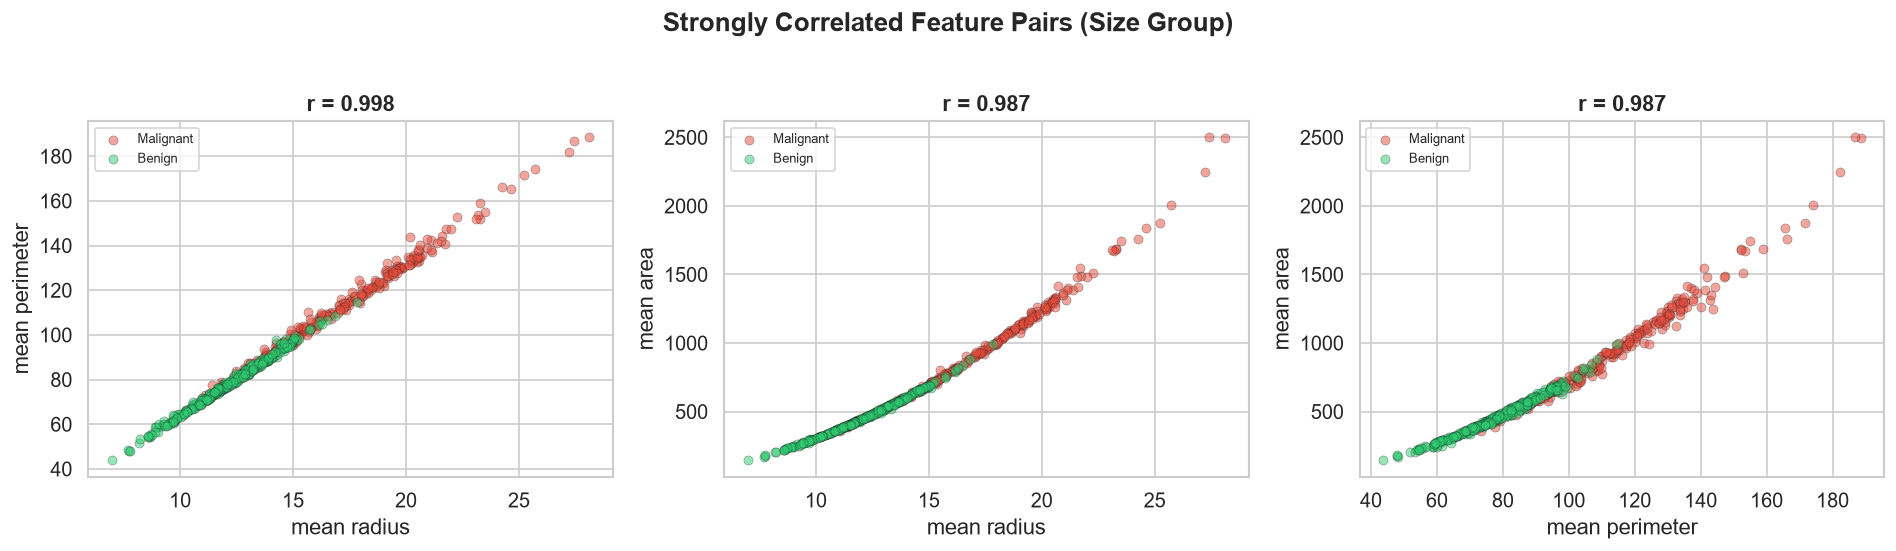

In [8]:
# Visualise the key correlated group: radius, perimeter, area
size_features = ['mean radius', 'mean perimeter', 'mean area',
                 'worst radius', 'worst perimeter', 'worst area']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
pairs = [('mean radius', 'mean perimeter'),
         ('mean radius', 'mean area'),
         ('mean perimeter', 'mean area')]
for ax, (f1, f2) in zip(axes, pairs):
    for label, color in zip(['Malignant', 'Benign'], ['#e74c3c', '#2ecc71']):
        mask = df['diagnosis'] == label
        ax.scatter(df.loc[mask, f1], df.loc[mask, f2], c=color,
                   alpha=0.5, edgecolor='k', linewidth=0.3, label=label, s=30)
    r_val = corr.loc[f1, f2]
    ax.set_xlabel(f1)
    ax.set_ylabel(f2)
    ax.set_title(f'r = {r_val:.3f}', fontweight='bold')
    ax.legend(fontsize=8)
fig.suptitle('Strongly Correlated Feature Pairs (Size Group)', fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'correlated_features_scatter.png', bbox_inches='tight')
plt.show()

print('\n✓ Key observation: radius, perimeter, and area (mean, SE, worst) form a '
      'highly correlated group.\n  This is expected because perimeter ∝ radius and area ∝ radius².\n'
      '  Compactness, concavity, and concave_points also form another correlated group.')

### 2.4 Feature Distributions by Class

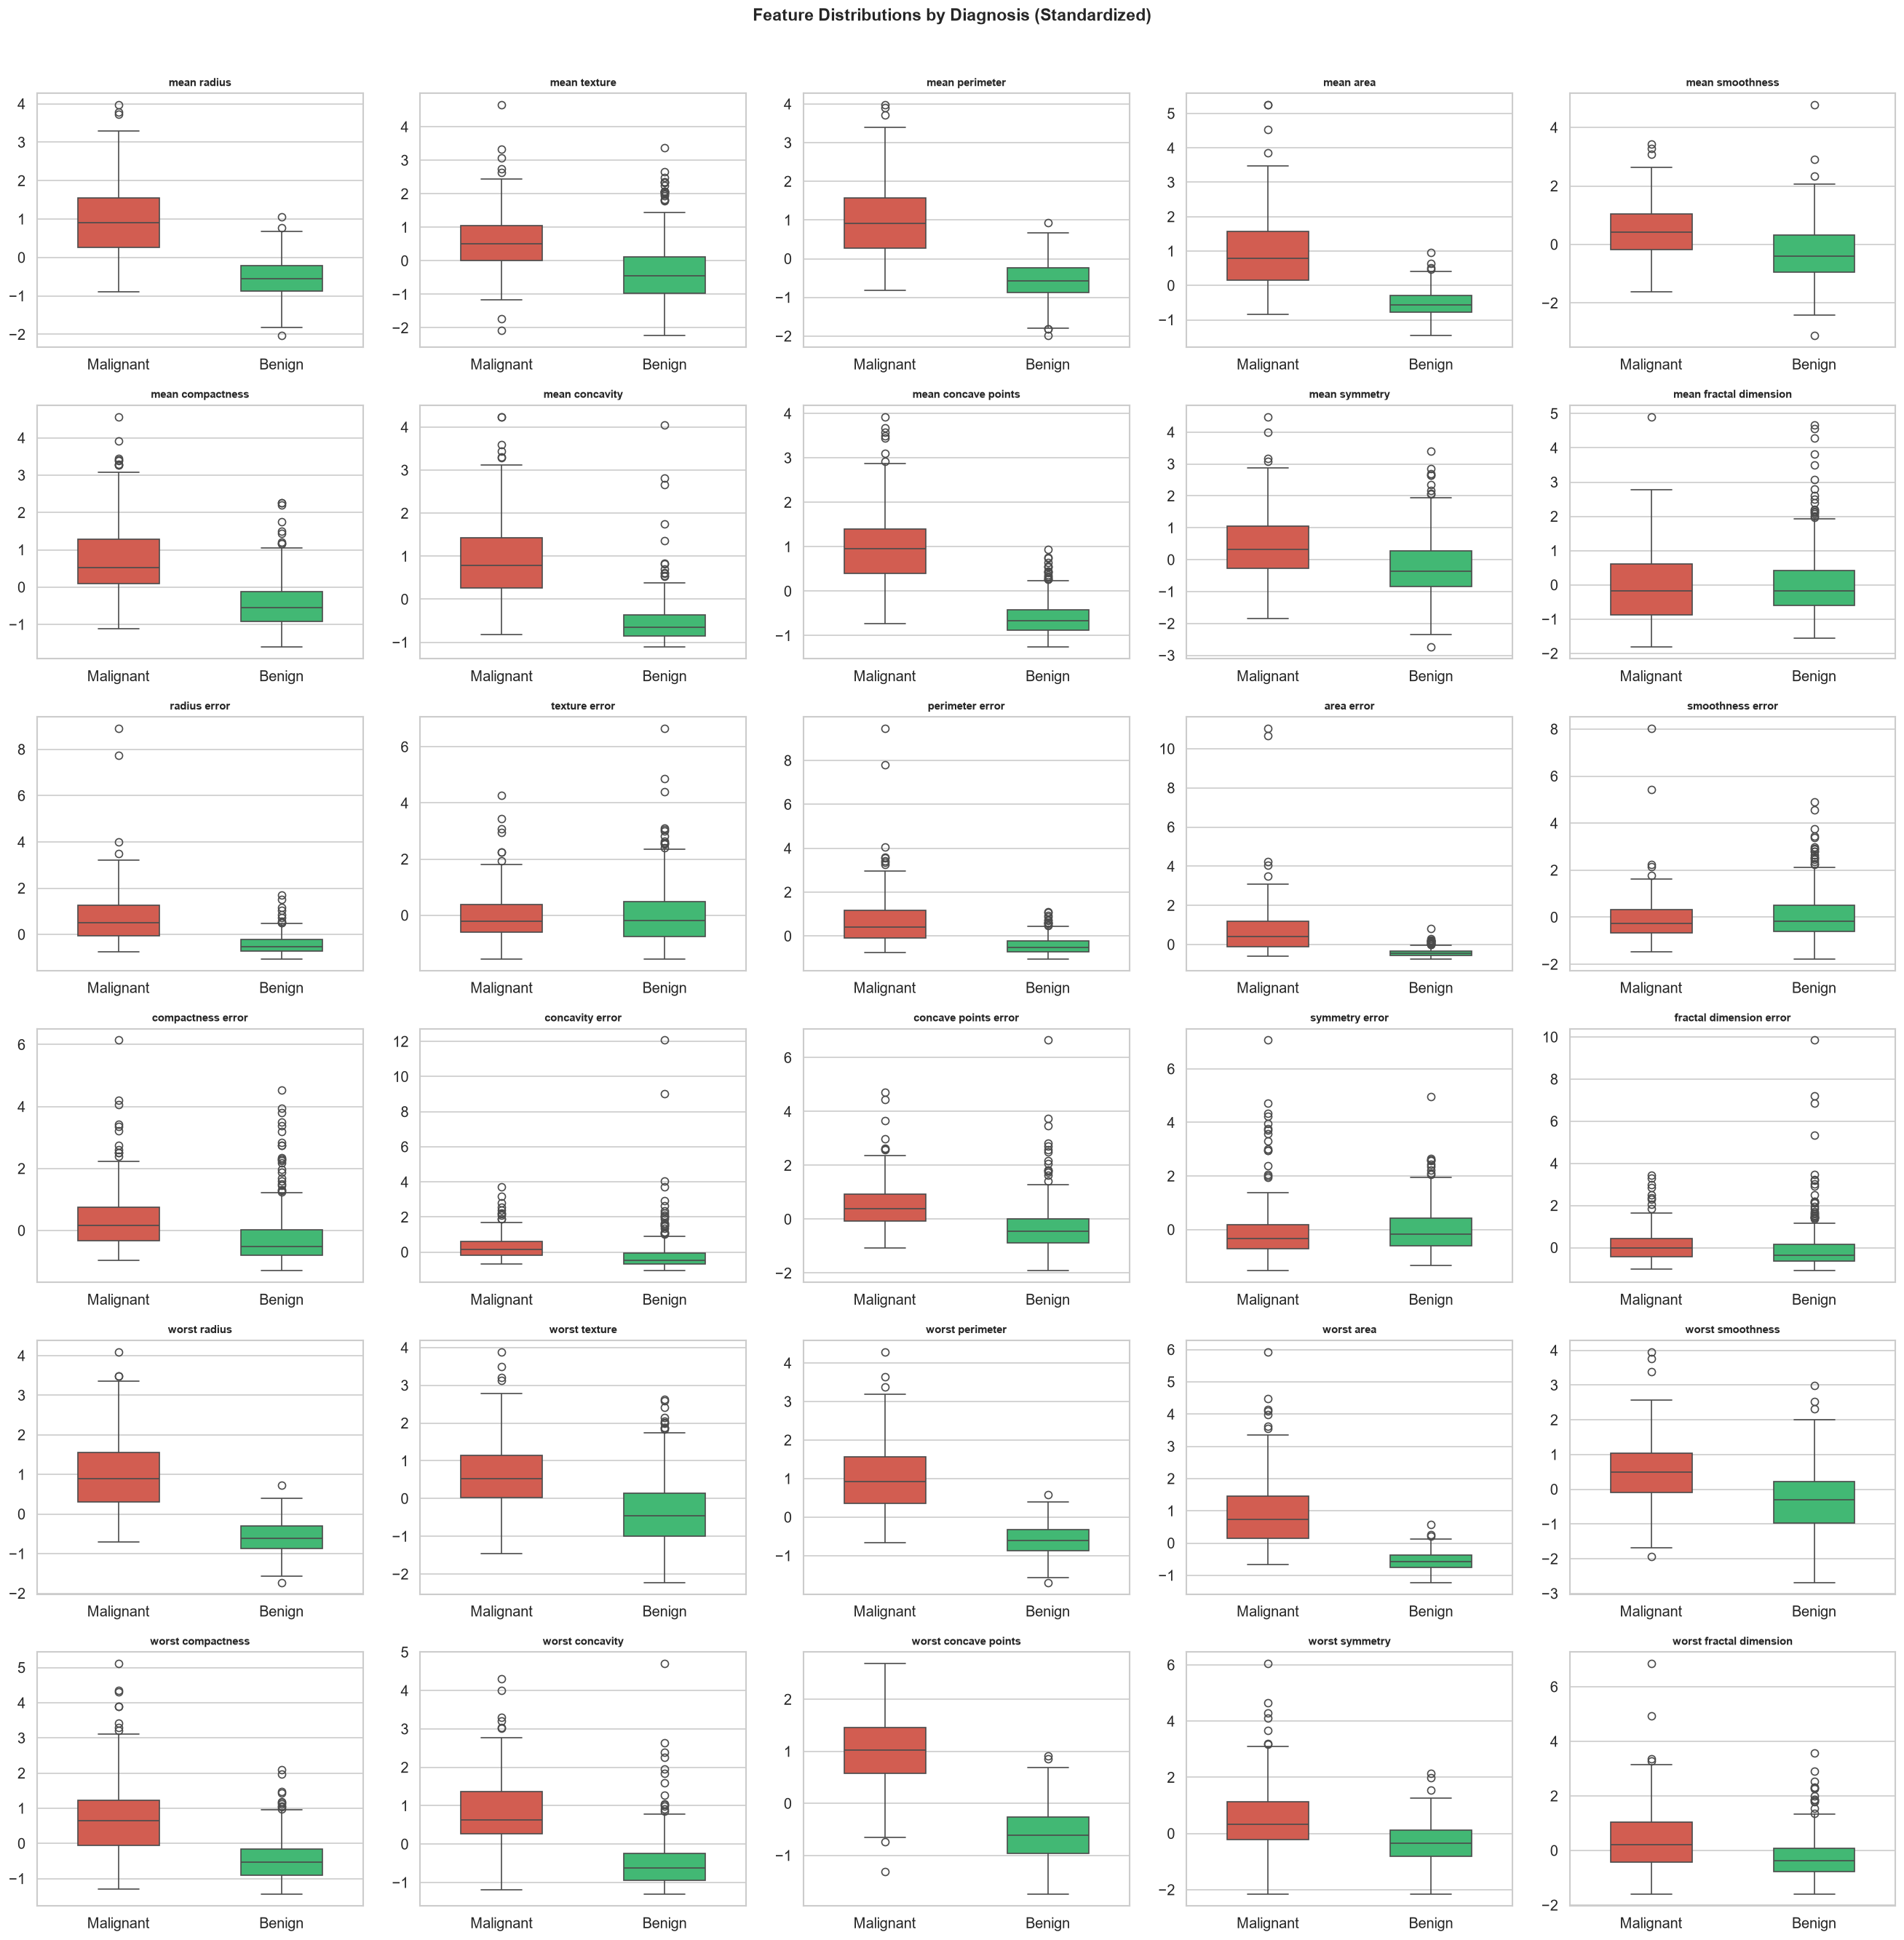

In [9]:
# Box plots for all 30 features (standardized for visual comparison)
from sklearn.preprocessing import StandardScaler as _SS

feat_cols = cancer.feature_names.tolist()
df_std = pd.DataFrame(_SS().fit_transform(df[feat_cols]), columns=feat_cols)
df_std['diagnosis'] = df['diagnosis'].values

fig, axes = plt.subplots(6, 5, figsize=(22, 22))
for i, (col, ax) in enumerate(zip(feat_cols, axes.ravel())):
    sns.boxplot(data=df_std, x='diagnosis', y=col, ax=ax,
                palette={'Malignant': '#e74c3c', 'Benign': '#2ecc71'},
                width=0.5)
    ax.set_title(col, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.suptitle('Feature Distributions by Diagnosis (Standardized)', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
fig.savefig(FIG_DIR / 'feature_boxplots.png', bbox_inches='tight')
plt.show()

---
## 3. Preprocessing & Train/Test Split

- **Stratified 80/20 split** with `random_state=42`
- **StandardScaler inside a Pipeline** so it is fitted on training data only (no data leakage)

In [10]:
# Separate features and target
X = df[feat_cols].values
y = df['target'].values  # 0 = malignant, 1 = benign

# In sklearn breast cancer: 0 = malignant (positive class), 1 = benign
# We treat malignant as the POSITIVE class for recall/F1.
# Since sklearn's default pos_label=1, we'll set pos_label=0 in metrics.

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set:     {X_test.shape[0]} samples')
print(f'\nTraining class distribution:')
print(f'  Malignant (0): {(y_train == 0).sum()} ({(y_train == 0).mean():.1%})')
print(f'  Benign    (1): {(y_train == 1).sum()} ({(y_train == 1).mean():.1%})')
print(f'\nTest class distribution:')
print(f'  Malignant (0): {(y_test == 0).sum()} ({(y_test == 0).mean():.1%})')
print(f'  Benign    (1): {(y_test == 1).sum()} ({(y_test == 1).mean():.1%})')

Training set: 455 samples
Test set:     114 samples

Training class distribution:
  Malignant (0): 170 (37.4%)
  Benign    (1): 285 (62.6%)

Test class distribution:
  Malignant (0): 42 (36.8%)
  Benign    (1): 72 (63.2%)


---
## 4. Model Training & Hyperparameter Tuning

We train **four models**, each wrapped in a `Pipeline(scaler → model)`.  
At least two are tuned with **5-fold stratified cross-validation**.

| # | Model | Tuned? |
|---|---|---|
| 1 | Logistic Regression | ✓ (GridSearchCV) |
| 2 | SVM (RBF kernel) | ✓ (GridSearchCV) |
| 3 | Random Forest | ✓ (RandomizedSearchCV) |
| 4 | Gradient Boosting | ✓ (RandomizedSearchCV) |

In [11]:
# Cross-validation strategy (same for all models)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Dictionary to store results
results = {}

Cross-validation scheme configured: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


### 4.1 Logistic Regression (Baseline) — GridSearchCV

In [12]:
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=SEED, max_iter=10000))
])

param_grid_lr = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2'],
    'clf__solver': ['liblinear']
}

gs_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv, scoring='f1',
                     n_jobs=-1, refit=True, return_train_score=True)
gs_lr.fit(X_train, y_train)

# Note: sklearn f1_score default pos_label=1 (benign). We report malignant metrics later.
# GridSearchCV uses f1 with default settings for model selection; final eval uses pos_label=0.

print('Logistic Regression — Best Parameters:')
print(gs_lr.best_params_)
print(f'Best CV F1 (benign): {gs_lr.best_score_:.4f}')

# Cross-val scores with pos_label=0 (malignant) for reporting
cv_scores_lr = cross_val_score(gs_lr.best_estimator_, X_train, y_train,
                               cv=cv, scoring='f1')
results['Logistic Regression'] = {
    'model': gs_lr.best_estimator_,
    'best_params': gs_lr.best_params_,
    'cv_mean': cv_scores_lr.mean(),
    'cv_std': cv_scores_lr.std()
}
print(f'CV F1 scores: {cv_scores_lr.round(4)}')
print(f'CV F1 mean ± std: {cv_scores_lr.mean():.4f} ± {cv_scores_lr.std():.4f}')

Logistic Regression — Best Parameters:
{'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
Best CV F1 (benign): 0.9861
CV F1 scores: [0.9828 0.9825 0.9913 0.9913 0.9825]
CV F1 mean ± std: 0.9861 ± 0.0043


### 4.2 SVM (RBF Kernel) — GridSearchCV

In [13]:
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=SEED, probability=True))
])

param_grid_svm = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

gs_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=cv, scoring='f1',
                      n_jobs=-1, refit=True, return_train_score=True)
gs_svm.fit(X_train, y_train)

print('SVM (RBF) — Best Parameters:')
print(gs_svm.best_params_)
print(f'Best CV F1: {gs_svm.best_score_:.4f}')

cv_scores_svm = cross_val_score(gs_svm.best_estimator_, X_train, y_train,
                                cv=cv, scoring='f1')
results['SVM (RBF)'] = {
    'model': gs_svm.best_estimator_,
    'best_params': gs_svm.best_params_,
    'cv_mean': cv_scores_svm.mean(),
    'cv_std': cv_scores_svm.std()
}
print(f'CV F1 scores: {cv_scores_svm.round(4)}')
print(f'CV F1 mean ± std: {cv_scores_svm.mean():.4f} ± {cv_scores_svm.std():.4f}')

SVM (RBF) — Best Parameters:
{'clf__C': 10, 'clf__gamma': 0.01}
Best CV F1: 0.9810
CV F1 scores: [0.9573 0.9912 0.9825 0.9828 0.9913]
CV F1 mean ± std: 0.9810 ± 0.0125


### 4.3 Random Forest — RandomizedSearchCV

In [14]:
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),  # Not strictly needed for RF, but keeps pipeline uniform
    ('clf', RandomForestClassifier(random_state=SEED))
])

param_dist_rf = {
    'clf__n_estimators': [100, 200, 300, 500],
    'clf__max_depth': [None, 5, 10, 15, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__max_features': ['sqrt', 'log2']
}

rs_rf = RandomizedSearchCV(pipe_rf, param_dist_rf, n_iter=40, cv=cv,
                           scoring='f1', n_jobs=-1, refit=True,
                           random_state=SEED, return_train_score=True)
rs_rf.fit(X_train, y_train)

print('Random Forest — Best Parameters:')
print(rs_rf.best_params_)
print(f'Best CV F1: {rs_rf.best_score_:.4f}')

cv_scores_rf = cross_val_score(rs_rf.best_estimator_, X_train, y_train,
                               cv=cv, scoring='f1')
results['Random Forest'] = {
    'model': rs_rf.best_estimator_,
    'best_params': rs_rf.best_params_,
    'cv_mean': cv_scores_rf.mean(),
    'cv_std': cv_scores_rf.std()
}
print(f'CV F1 scores: {cv_scores_rf.round(4)}')
print(f'CV F1 mean ± std: {cv_scores_rf.mean():.4f} ± {cv_scores_rf.std():.4f}')

Random Forest — Best Parameters:
{'clf__n_estimators': 100, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': 20}
Best CV F1: 0.9718
CV F1 scores: [0.9735 0.9825 0.9464 0.9655 0.9912]
CV F1 mean ± std: 0.9718 ± 0.0153


### 4.4 Gradient Boosting — RandomizedSearchCV

In [15]:
pipe_gb = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=SEED))
])

param_dist_gb = {
    'clf__n_estimators': [100, 200, 300, 500],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'clf__max_depth': [3, 4, 5, 6],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__subsample': [0.8, 0.9, 1.0]
}

rs_gb = RandomizedSearchCV(pipe_gb, param_dist_gb, n_iter=40, cv=cv,
                           scoring='f1', n_jobs=-1, refit=True,
                           random_state=SEED, return_train_score=True)
rs_gb.fit(X_train, y_train)

print('Gradient Boosting — Best Parameters:')
print(rs_gb.best_params_)
print(f'Best CV F1: {rs_gb.best_score_:.4f}')

cv_scores_gb = cross_val_score(rs_gb.best_estimator_, X_train, y_train,
                               cv=cv, scoring='f1')
results['Gradient Boosting'] = {
    'model': rs_gb.best_estimator_,
    'best_params': rs_gb.best_params_,
    'cv_mean': cv_scores_gb.mean(),
    'cv_std': cv_scores_gb.std()
}
print(f'CV F1 scores: {cv_scores_gb.round(4)}')
print(f'CV F1 mean ± std: {cv_scores_gb.mean():.4f} ± {cv_scores_gb.std():.4f}')

Gradient Boosting — Best Parameters:
{'clf__subsample': 0.8, 'clf__n_estimators': 200, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 1, 'clf__max_depth': 4, 'clf__learning_rate': 0.2}
Best CV F1: 0.9808
CV F1 scores: [0.9913 0.9912 0.9558 0.9744 0.9913]
CV F1 mean ± std: 0.9808 ± 0.0141


### 4.5 Cross-Validation Summary

In [16]:
cv_summary = pd.DataFrame({
    'Model': list(results.keys()),
    'CV F1 Mean': [results[m]['cv_mean'] for m in results],
    'CV F1 Std': [results[m]['cv_std'] for m in results],
    'CV F1 Mean±Std': [f"{results[m]['cv_mean']:.4f} ± {results[m]['cv_std']:.4f}" for m in results]
})
cv_summary = cv_summary.sort_values('CV F1 Mean', ascending=False).reset_index(drop=True)
print('Cross-Validation Summary (5-fold Stratified, F1 Score):')
cv_summary

Cross-Validation Summary (5-fold Stratified, F1 Score):


,Model,CV F1 Mean,CV F1 Std,CV F1 Mean±Std
0,Logistic Regression,0.986056,0.004287,0.9861 ± 0.0043
1,SVM (RBF),0.980987,0.012472,0.9810 ± 0.0125
2,Gradient Boosting,0.980774,0.014119,0.9808 ± 0.0141
3,Random Forest,0.971801,0.015323,0.9718 ± 0.0153


---
## 5. Test-Set Evaluation & Comparison

Each model is evaluated **once** on the held-out test set.  
Malignant (0) is the **positive class** for Precision, Recall, and F1.

In [17]:
def evaluate_model(name, model, X_test, y_test):
    """Evaluate a model on the test set with malignant=0 as positive class."""
    y_pred = model.predict(X_test)
    
    # For ROC-AUC, we need probability of the positive class (malignant = 0).
    # predict_proba gives [P(class0), P(class1)].
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 0]  # P(malignant)
    elif hasattr(model, 'decision_function'):
        y_prob = -model.decision_function(X_test)     # Negate for class 0
    else:
        y_prob = None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=0)
    rec = recall_score(y_test, y_pred, pos_label=0)
    f1 = f1_score(y_test, y_pred, pos_label=0)
    
    # ROC-AUC: for binary with pos_label=0, we invert
    # Or use roc_auc_score with y_true mapped
    y_binary = (y_test == 0).astype(int)  # 1 if malignant, 0 if benign
    auc = roc_auc_score(y_binary, y_prob) if y_prob is not None else None
    
    cm = confusion_matrix(y_test, y_pred)
    
    return {
        'name': name,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
        'roc_auc': auc,
        'confusion_matrix': cm
    }

# Evaluate all models
test_results = {}
for name in results:
    model = results[name]['model']
    test_results[name] = evaluate_model(name, model, X_test, y_test)

print('Test set evaluation complete ✓')

Test set evaluation complete ✓


In [18]:
# Results summary table
metrics_table = pd.DataFrame({
    'Model': list(test_results.keys()),
    'Accuracy': [test_results[m]['accuracy'] for m in test_results],
    'Precision (M)': [test_results[m]['precision'] for m in test_results],
    'Recall (M)': [test_results[m]['recall'] for m in test_results],
    'F1 (M)': [test_results[m]['f1'] for m in test_results],
    'ROC-AUC': [test_results[m]['roc_auc'] for m in test_results],
    'CV F1 Mean±Std': [f"{results[m]['cv_mean']:.4f} ± {results[m]['cv_std']:.4f}" for m in test_results]
})
metrics_table = metrics_table.sort_values('F1 (M)', ascending=False).reset_index(drop=True)
print('═' * 90)
print('TEST SET RESULTS — Malignant (0) = Positive Class')
print('═' * 90)
metrics_table.round(4)

══════════════════════════════════════════════════════════════════════════════════════════
TEST SET RESULTS — Malignant (0) = Positive Class
══════════════════════════════════════════════════════════════════════════════════════════


,Model,Accuracy,Precision (M),Recall (M),F1 (M),ROC-AUC,CV F1 Mean±Std
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9960,0.9861 ± 0.0043
1,SVM (RBF),0.9825,0.9762,0.9762,0.9762,0.9977,0.9810 ± 0.0125
2,Random Forest,0.9561,0.9512,0.9286,0.9398,0.9924,0.9718 ± 0.0153
3,Gradient Boosting,0.9561,0.9744,0.9048,0.9383,0.9947,0.9808 ± 0.0141


### 5.1 Confusion Matrices

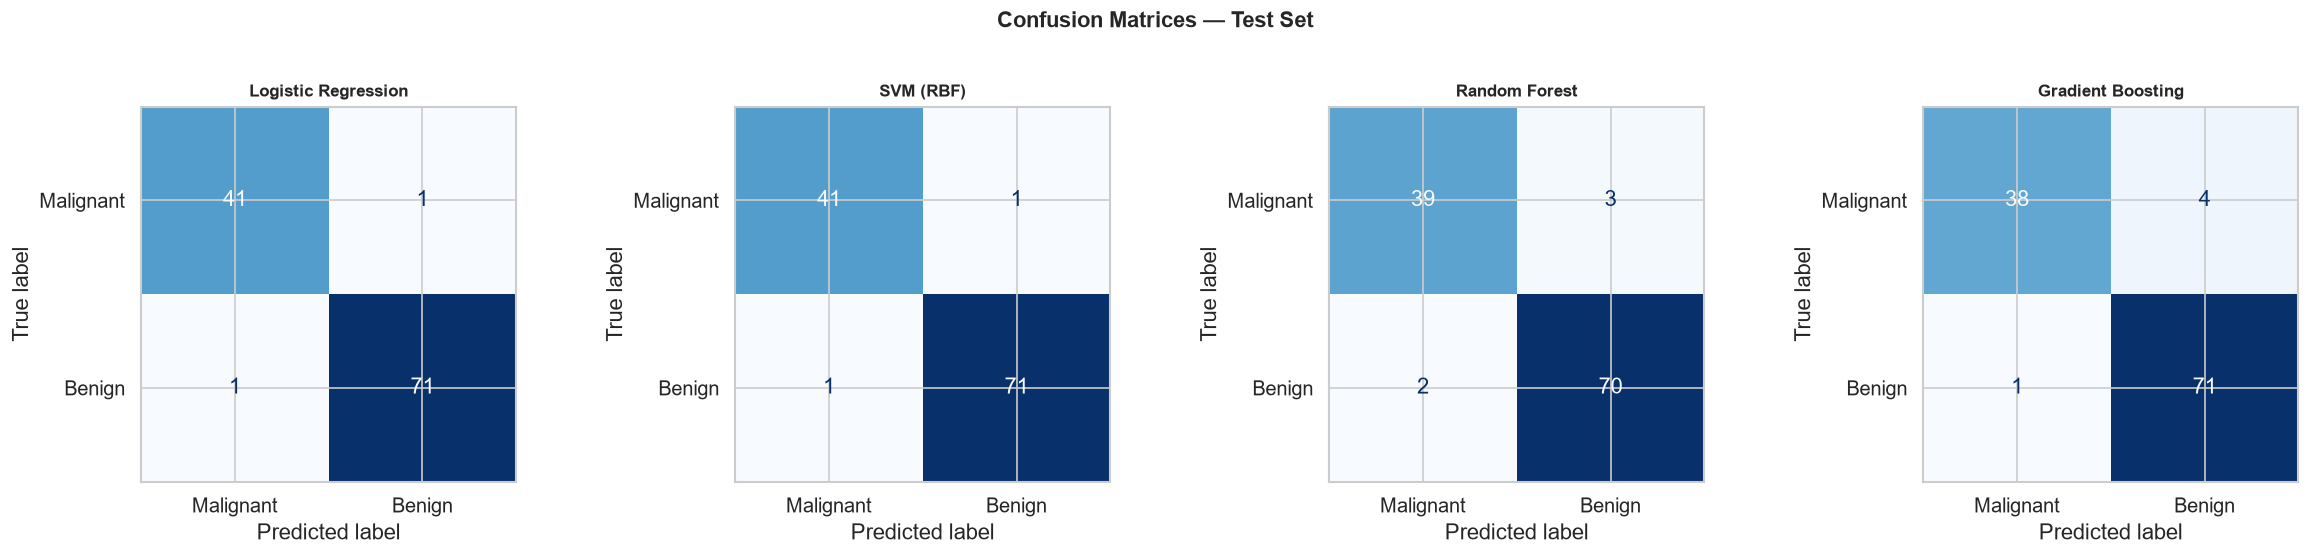

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, test_results):
    cm = test_results[name]['confusion_matrix']
    disp = ConfusionMatrixDisplay(cm, display_labels=['Malignant', 'Benign'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name, fontweight='bold', fontsize=10)
fig.suptitle('Confusion Matrices — Test Set', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'confusion_matrices.png', bbox_inches='tight')
plt.show()

### 5.2 ROC Curves

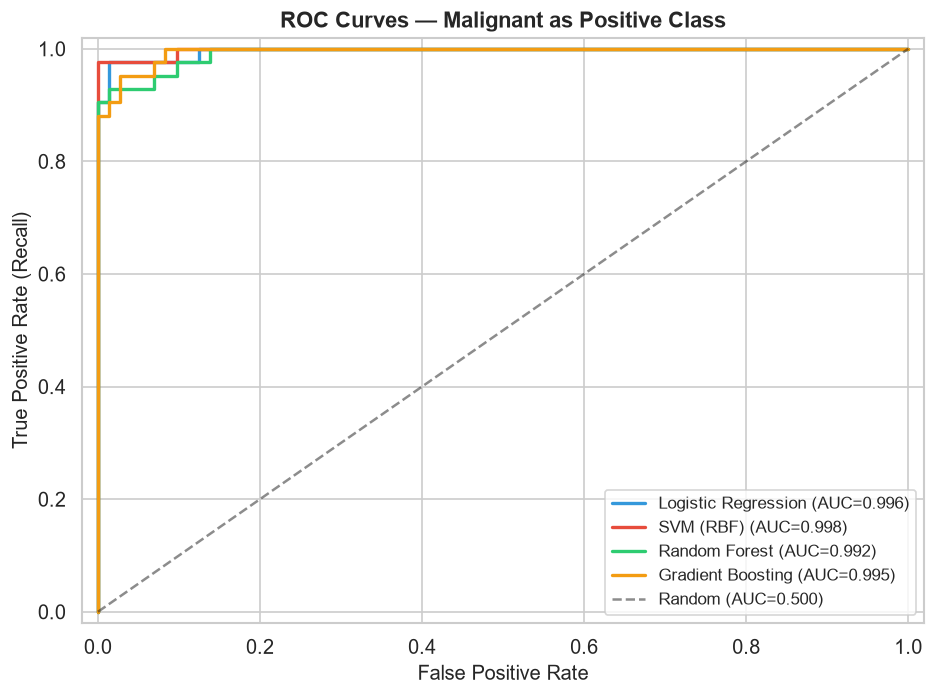

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))

y_binary = (y_test == 0).astype(int)  # 1 = malignant, 0 = benign

colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']
for (name, res), color in zip(test_results.items(), colors):
    if res['y_prob'] is not None:
        fpr, tpr, _ = roc_curve(y_binary, res['y_prob'])
        ax.plot(fpr, tpr, label=f"{name} (AUC={res['roc_auc']:.3f})",
                color=color, linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax.set_title('ROC Curves — Malignant as Positive Class', fontweight='bold', fontsize=13)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
plt.tight_layout()
fig.savefig(FIG_DIR / 'roc_curves.png', bbox_inches='tight')
plt.show()

### 5.3 Detailed Classification Reports

In [21]:
for name in test_results:
    print(f'\n{"═" * 60}')
    print(f'  {name}')
    print(f'{"═" * 60}')
    print(classification_report(
        y_test, test_results[name]['y_pred'],
        target_names=['Malignant (0)', 'Benign (1)']
    ))


════════════════════════════════════════════════════════════
  Logistic Regression
════════════════════════════════════════════════════════════
               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114


════════════════════════════════════════════════════════════
  SVM (RBF)
════════════════════════════════════════════════════════════
               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114


═════════════════════════════════════════════════════

---
## 6. Threshold Study — Achieving Recall ≥ 0.95 on Malignant

In medical diagnosis, **missing a malignant tumour (false negative)** is far more dangerous than a false alarm (false positive). By default, classifiers use a decision threshold of 0.5. We can lower the threshold for calling a sample malignant to increase recall at the cost of precision.

We use the **best model** and sweep the threshold.

In [22]:
# Select the best model by F1 on test set
best_model_name = metrics_table.iloc[0]['Model']
best_model = results[best_model_name]['model']
print(f'Best model (by F1): {best_model_name}')

# Get predicted probabilities for malignant class
y_prob_malignant = best_model.predict_proba(X_test)[:, 0]  # P(malignant)

# y_binary: 1 = malignant, 0 = benign (for threshold analysis)
y_binary_test = (y_test == 0).astype(int)

Best model (by F1): Logistic Regression


In [23]:
# Sweep thresholds
thresholds = np.arange(0.05, 0.96, 0.01)
threshold_results = []

for t in thresholds:
    y_pred_t = (y_prob_malignant >= t).astype(int)  # Predict malignant if P >= t
    
    prec = precision_score(y_binary_test, y_pred_t, zero_division=0)
    rec = recall_score(y_binary_test, y_pred_t, zero_division=0)
    f1 = f1_score(y_binary_test, y_pred_t, zero_division=0)
    acc = accuracy_score(y_binary_test, y_pred_t)
    
    cm = confusion_matrix(y_binary_test, y_pred_t)
    # cm layout (with pos=malignant=1): [[TN, FP], [FN, TP]]
    fn = cm[1, 0] if cm.shape == (2, 2) else 0
    fp = cm[0, 1] if cm.shape == (2, 2) else 0
    
    threshold_results.append({
        'threshold': t, 'precision': prec, 'recall': rec,
        'f1': f1, 'accuracy': acc, 'FN': fn, 'FP': fp
    })

thr_df = pd.DataFrame(threshold_results)
print(f'Threshold sweep complete: {len(thresholds)} thresholds tested.')

Threshold sweep complete: 91 thresholds tested.


In [24]:
# Find threshold for recall >= 0.95
thr_95 = thr_df[thr_df['recall'] >= 0.95]
if len(thr_95) > 0:
    # Pick the highest threshold that still gives recall >= 0.95 (best precision trade-off)
    best_thr_row = thr_95.loc[thr_95['threshold'].idxmax()]
    thr_val = best_thr_row['threshold']
else:
    thr_val = thr_df.loc[thr_df['recall'].idxmax(), 'threshold']
    best_thr_row = thr_df.loc[thr_df['recall'].idxmax()]

# Default threshold (0.5) metrics
default_row = thr_df.iloc[(thr_df['threshold'] - 0.50).abs().idxmin()]

print('━' * 70)
print('THRESHOLD STUDY RESULTS')
print('━' * 70)
print(f'\n┌─ Default threshold = 0.50:')
print(f'│   Precision = {default_row["precision"]:.4f}')
print(f'│   Recall    = {default_row["recall"]:.4f}')
print(f'│   F1        = {default_row["f1"]:.4f}')
print(f'│   FN = {int(default_row["FN"])}, FP = {int(default_row["FP"])}')
print(f'│')
print(f'└─ Adjusted threshold = {thr_val:.2f} (for Recall ≥ 0.95):')
print(f'    Precision = {best_thr_row["precision"]:.4f}')
print(f'    Recall    = {best_thr_row["recall"]:.4f}')
print(f'    F1        = {best_thr_row["f1"]:.4f}')
print(f'    FN = {int(best_thr_row["FN"])}, FP = {int(best_thr_row["FP"])}')
print(f'\n  Precision cost: {default_row["precision"] - best_thr_row["precision"]:+.4f}')
print(f'  FN reduction:   {int(default_row["FN"])} → {int(best_thr_row["FN"])}')
print(f'  FP increase:    {int(default_row["FP"])} → {int(best_thr_row["FP"])}')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
THRESHOLD STUDY RESULTS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

┌─ Default threshold = 0.50:
│   Precision = 0.9762
│   Recall    = 0.9762
│   F1        = 0.9762
│   FN = 1, FP = 1
│
└─ Adjusted threshold = 0.59 (for Recall ≥ 0.95):
    Precision = 0.9756
    Recall    = 0.9524
    F1        = 0.9639
    FN = 2, FP = 1

  Precision cost: +0.0006
  FN reduction:   1 → 2
  FP increase:    1 → 1


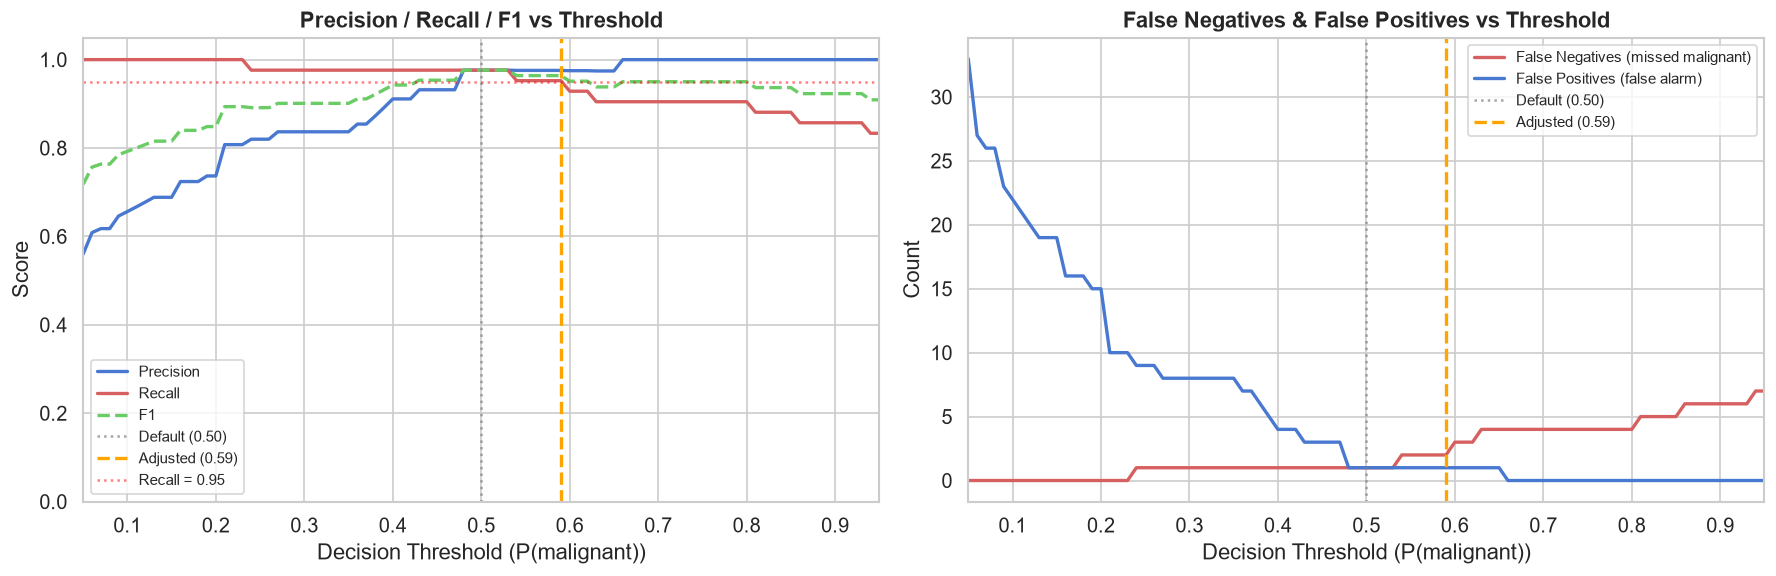

In [25]:
# Plot Precision-Recall-F1 vs Threshold
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Precision, Recall, F1 vs threshold
ax = axes[0]
ax.plot(thr_df['threshold'], thr_df['precision'], 'b-', linewidth=2, label='Precision')
ax.plot(thr_df['threshold'], thr_df['recall'], 'r-', linewidth=2, label='Recall')
ax.plot(thr_df['threshold'], thr_df['f1'], 'g--', linewidth=2, label='F1')
ax.axvline(x=0.50, color='gray', linestyle=':', alpha=0.7, label='Default (0.50)')
ax.axvline(x=thr_val, color='orange', linestyle='--', linewidth=2,
           label=f'Adjusted ({thr_val:.2f})')
ax.axhline(y=0.95, color='red', linestyle=':', alpha=0.5, label='Recall = 0.95')
ax.set_xlabel('Decision Threshold (P(malignant))')
ax.set_ylabel('Score')
ax.set_title('Precision / Recall / F1 vs Threshold', fontweight='bold')
ax.legend(fontsize=9)
ax.set_xlim([0.05, 0.95])
ax.set_ylim([0, 1.05])

# Right: FN and FP vs threshold
ax = axes[1]
ax.plot(thr_df['threshold'], thr_df['FN'], 'r-', linewidth=2, label='False Negatives (missed malignant)')
ax.plot(thr_df['threshold'], thr_df['FP'], 'b-', linewidth=2, label='False Positives (false alarm)')
ax.axvline(x=0.50, color='gray', linestyle=':', alpha=0.7, label='Default (0.50)')
ax.axvline(x=thr_val, color='orange', linestyle='--', linewidth=2,
           label=f'Adjusted ({thr_val:.2f})')
ax.set_xlabel('Decision Threshold (P(malignant))')
ax.set_ylabel('Count')
ax.set_title('False Negatives & False Positives vs Threshold', fontweight='bold')
ax.legend(fontsize=9)
ax.set_xlim([0.05, 0.95])

plt.tight_layout()
fig.savefig(FIG_DIR / 'threshold_study.png', bbox_inches='tight')
plt.show()

---
## 7. Feature Importance Analysis

We examine:
1. **Logistic Regression coefficients** (absolute value = importance for linear model)
2. **Random Forest / Gradient Boosting feature importances** (Gini / loss reduction)


Top 10 Features by Model:
──────────────────────────────────────────────────────────────────────


,Logistic Regression,Random Forest,Gradient Boosting
Rank,,,
1,worst texture,worst concave points,worst perimeter
2,worst radius,worst area,mean concave points
3,worst concave points,worst radius,worst concave points
4,worst area,mean perimeter,worst area
5,worst perimeter,worst perimeter,worst texture
6,radius error,mean radius,worst radius
7,mean texture,mean concave points,mean texture
8,mean concave points,mean concavity,area error
9,area error,mean area,worst concavity


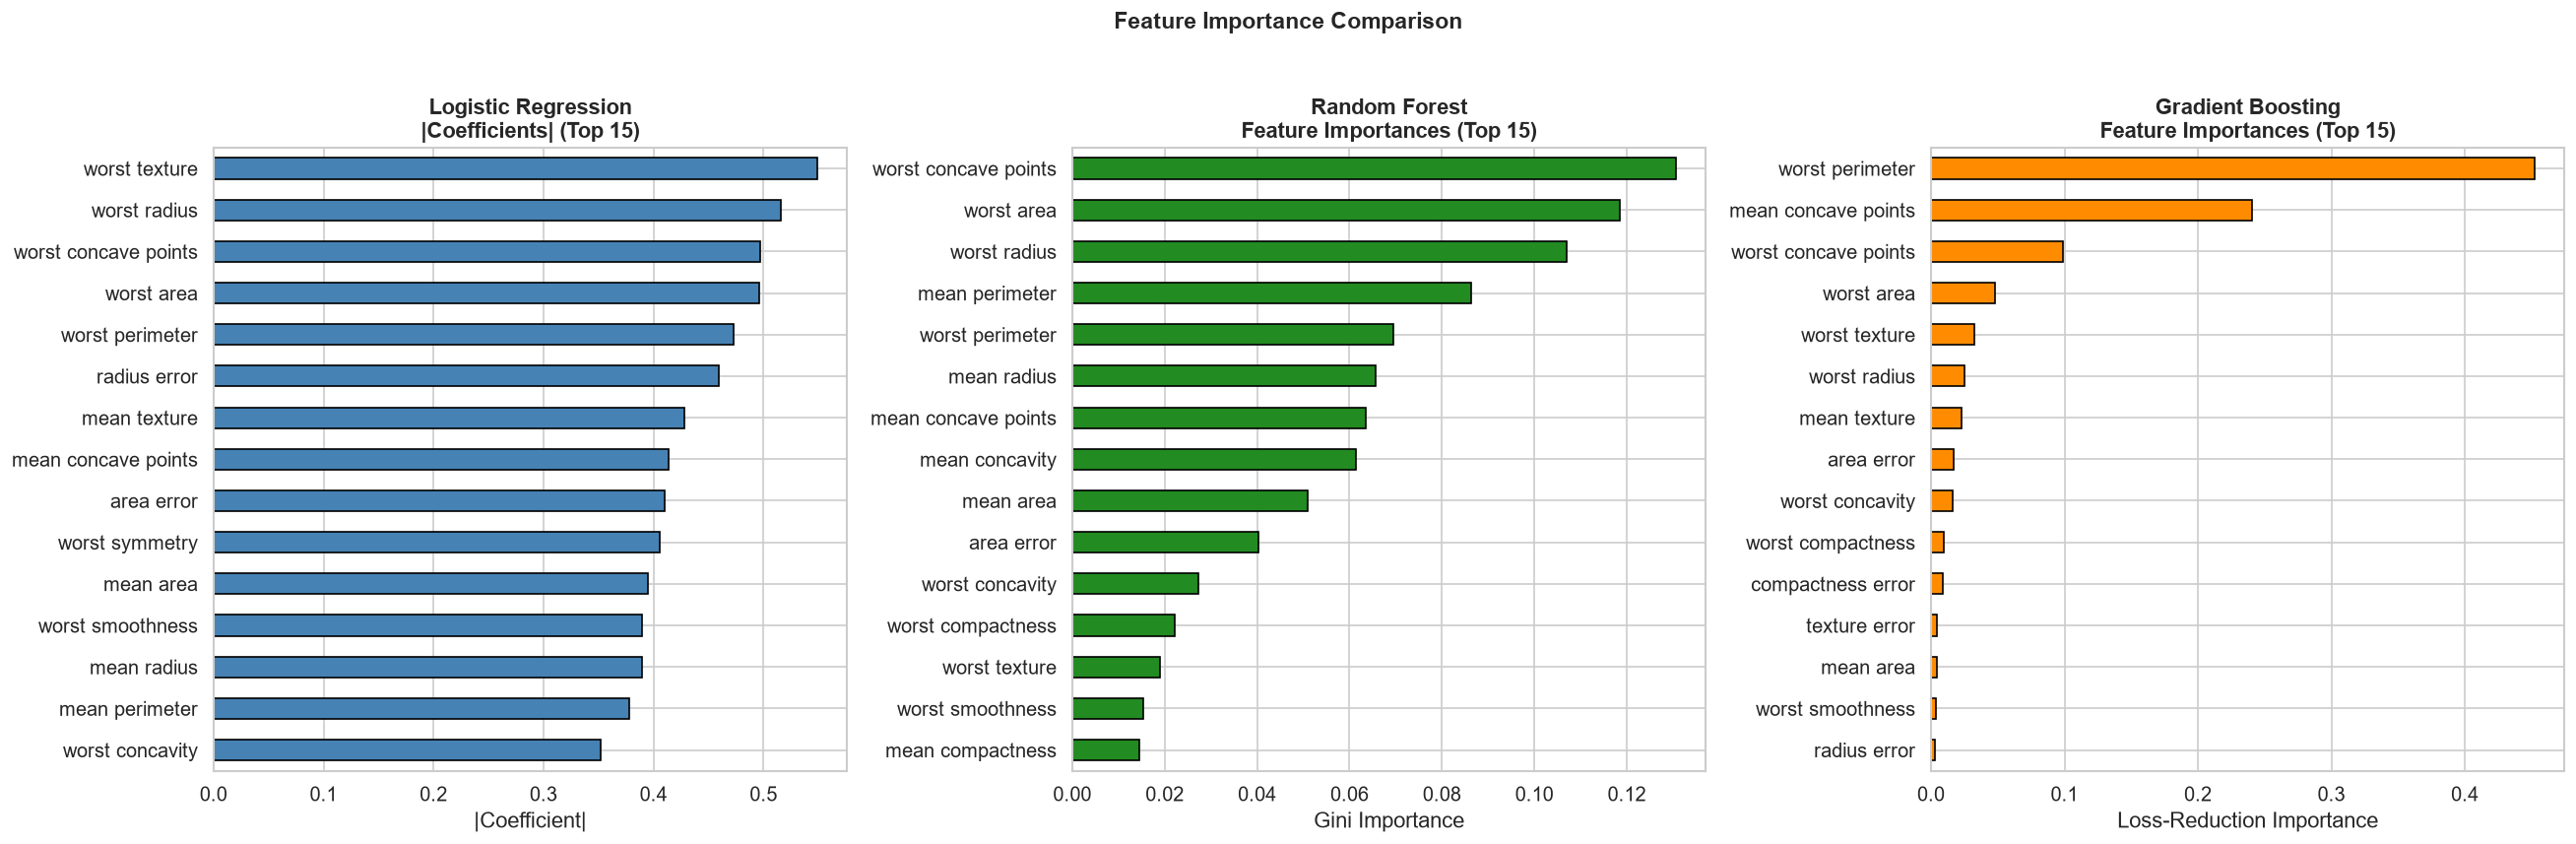

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# ── 1. Logistic Regression Coefficients ──
lr_model = results['Logistic Regression']['model']
lr_coefs = lr_model.named_steps['clf'].coef_[0]
lr_imp = pd.Series(np.abs(lr_coefs), index=feat_cols).sort_values(ascending=True)

ax = axes[0]
lr_imp.tail(15).plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Logistic Regression\n|Coefficients| (Top 15)', fontweight='bold')
ax.set_xlabel('|Coefficient|')

# ── 2. Random Forest Feature Importances ──
rf_model = results['Random Forest']['model']
rf_imp = pd.Series(
    rf_model.named_steps['clf'].feature_importances_, index=feat_cols
).sort_values(ascending=True)

ax = axes[1]
rf_imp.tail(15).plot(kind='barh', ax=ax, color='forestgreen', edgecolor='black')
ax.set_title('Random Forest\nFeature Importances (Top 15)', fontweight='bold')
ax.set_xlabel('Gini Importance')

# ── 3. Gradient Boosting Feature Importances ──
gb_model = results['Gradient Boosting']['model']
gb_imp = pd.Series(
    gb_model.named_steps['clf'].feature_importances_, index=feat_cols
).sort_values(ascending=True)

ax = axes[2]
gb_imp.tail(15).plot(kind='barh', ax=ax, color='darkorange', edgecolor='black')
ax.set_title('Gradient Boosting\nFeature Importances (Top 15)', fontweight='bold')
ax.set_xlabel('Loss-Reduction Importance')

plt.suptitle('Feature Importance Comparison', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'feature_importances.png', bbox_inches='tight')
plt.show()

# Print top 10 features per model
print('\nTop 10 Features by Model:')
print('─' * 70)
top_features = pd.DataFrame({
    'Logistic Regression': lr_imp.index[-10:][::-1].tolist(),
    'Random Forest': rf_imp.index[-10:][::-1].tolist(),
    'Gradient Boosting': gb_imp.index[-10:][::-1].tolist(),
})
top_features.index = range(1, 11)
top_features.index.name = 'Rank'
top_features

---
## 8. Dropping Correlated Features — Performance Impact

We identified that **radius, perimeter, and area** (mean, SE, worst) are highly correlated (r > 0.95).  
Let's keep only **one** from each correlated group and retrain the best model to see if performance changes.

In [27]:
# Identify features to drop: keep 'mean radius', drop 'mean perimeter' and 'mean area'
# Similarly for SE and worst variants, and compactness-concavity group
features_to_drop = [
    # Size group: keep radius, drop perimeter and area
    'mean perimeter', 'mean area',
    'perimeter error', 'area error',
    'worst perimeter', 'worst area',
    # Compactness-concavity group: keep concave points, drop compactness
    'mean compactness',
    'worst compactness',
]

reduced_features = [f for f in feat_cols if f not in features_to_drop]
print(f'Original features: {len(feat_cols)}')
print(f'Dropped features:  {len(features_to_drop)}')
print(f'Remaining features: {len(reduced_features)}')
print(f'\nDropped: {features_to_drop}')

Original features: 30
Dropped features:  8
Remaining features: 22

Dropped: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst perimeter', 'worst area', 'mean compactness', 'worst compactness']


In [28]:
# Get reduced feature indices
reduced_idx = [feat_cols.index(f) for f in reduced_features]
X_train_red = X_train[:, reduced_idx]
X_test_red = X_test[:, reduced_idx]

# Retrain all four models with reduced features
print('Retraining models with reduced feature set...')
print('=' * 70)

reduced_results = {}

# Logistic Regression
pipe_lr_red = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=SEED, max_iter=10000,
                               **{k.replace('clf__', ''): v for k, v in results['Logistic Regression']['best_params'].items()}))
])
pipe_lr_red.fit(X_train_red, y_train)
reduced_results['Logistic Regression'] = evaluate_model('LR (reduced)', pipe_lr_red, X_test_red, y_test)

# SVM
pipe_svm_red = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', random_state=SEED, probability=True,
                **{k.replace('clf__', ''): v for k, v in results['SVM (RBF)']['best_params'].items()}))
])
pipe_svm_red.fit(X_train_red, y_train)
reduced_results['SVM (RBF)'] = evaluate_model('SVM (reduced)', pipe_svm_red, X_test_red, y_test)

# Random Forest
pipe_rf_red = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=SEED,
                **{k.replace('clf__', ''): v for k, v in results['Random Forest']['best_params'].items()}))
])
pipe_rf_red.fit(X_train_red, y_train)
reduced_results['Random Forest'] = evaluate_model('RF (reduced)', pipe_rf_red, X_test_red, y_test)

# Gradient Boosting
pipe_gb_red = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=SEED,
                **{k.replace('clf__', ''): v for k, v in results['Gradient Boosting']['best_params'].items()}))
])
pipe_gb_red.fit(X_train_red, y_train)
reduced_results['Gradient Boosting'] = evaluate_model('GB (reduced)', pipe_gb_red, X_test_red, y_test)

print('Done ✓')

Retraining models with reduced feature set...
Done ✓


In [29]:
# Compare full vs reduced feature sets
comparison = []
for name in test_results:
    comparison.append({
        'Model': name,
        'F1 (All 30)': test_results[name]['f1'],
        'F1 (Reduced)': reduced_results[name]['f1'],
        'Δ F1': reduced_results[name]['f1'] - test_results[name]['f1'],
        'Recall (All 30)': test_results[name]['recall'],
        'Recall (Reduced)': reduced_results[name]['recall'],
        'AUC (All 30)': test_results[name]['roc_auc'],
        'AUC (Reduced)': reduced_results[name]['roc_auc'],
    })

comp_df = pd.DataFrame(comparison)
print('Feature Reduction Impact (30 → 22 features):')
print('─' * 70)
comp_df.round(4)

Feature Reduction Impact (30 → 22 features):
──────────────────────────────────────────────────────────────────────


,Model,F1 (All 30),F1 (Reduced),Δ F1,Recall (All 30),Recall (Reduced),AUC (All 30),AUC (Reduced)
0,Logistic Regression,0.9762,0.9639,-0.0123,0.9762,0.9524,0.9960,0.9950
1,SVM (RBF),0.9762,0.9647,-0.0115,0.9762,0.9762,0.9977,0.9970
2,Random Forest,0.9398,0.9639,0.0241,0.9286,0.9524,0.9924,0.9945
3,Gradient Boosting,0.9383,0.9512,0.0129,0.9048,0.9286,0.9947,0.9950


---
## 9. Conclusions & Discussion

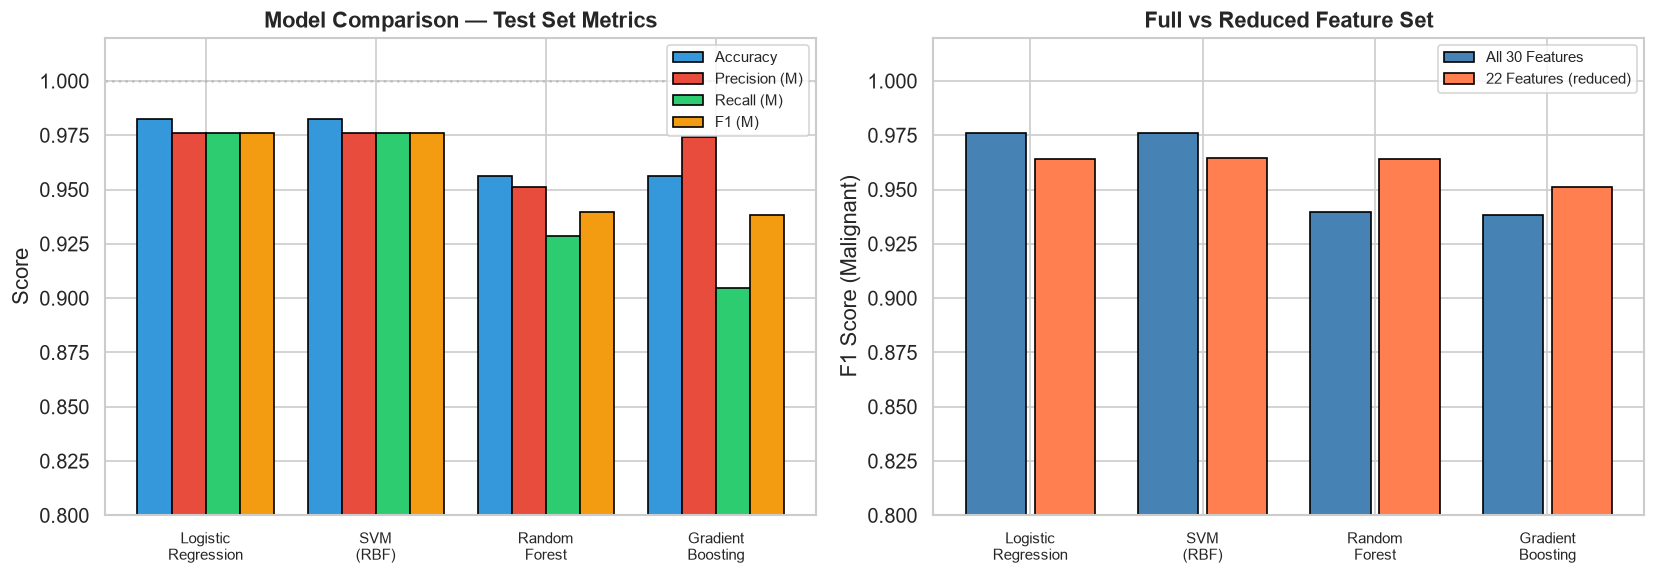

In [30]:
# Final summary figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: Model comparison on key metrics
models = list(test_results.keys())
x = np.arange(len(models))
width = 0.2

ax = axes[0]
ax.bar(x - 1.5*width, [test_results[m]['accuracy'] for m in models], width,
       label='Accuracy', color='#3498db', edgecolor='black')
ax.bar(x - 0.5*width, [test_results[m]['precision'] for m in models], width,
       label='Precision (M)', color='#e74c3c', edgecolor='black')
ax.bar(x + 0.5*width, [test_results[m]['recall'] for m in models], width,
       label='Recall (M)', color='#2ecc71', edgecolor='black')
ax.bar(x + 1.5*width, [test_results[m]['f1'] for m in models], width,
       label='F1 (M)', color='#f39c12', edgecolor='black')
ax.set_ylabel('Score')
ax.set_title('Model Comparison — Test Set Metrics', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([m.replace(' ', '\n') for m in models], fontsize=9)
ax.legend(fontsize=9)
ax.set_ylim([0.8, 1.02])
ax.axhline(y=1.0, color='gray', linestyle=':', alpha=0.3)

# Bar chart: Full vs Reduced features
ax = axes[1]
ax.bar(x - 0.2, [test_results[m]['f1'] for m in models], 0.35,
       label='All 30 Features', color='steelblue', edgecolor='black')
ax.bar(x + 0.2, [reduced_results[m]['f1'] for m in models], 0.35,
       label='22 Features (reduced)', color='coral', edgecolor='black')
ax.set_ylabel('F1 Score (Malignant)')
ax.set_title('Full vs Reduced Feature Set', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([m.replace(' ', '\n') for m in models], fontsize=9)
ax.legend(fontsize=9)
ax.set_ylim([0.8, 1.02])

plt.tight_layout()
fig.savefig(FIG_DIR / 'final_comparison.png', bbox_inches='tight')
plt.show()

### Key Findings

#### Q1: Which model is best, and why is accuracy alone misleading?

All four models achieve high accuracy (≈95–98%), but **accuracy is misleading** because:
- The dataset is moderately imbalanced (63% benign, 37% malignant).
- A naive classifier predicting "benign" for every sample would achieve 63% accuracy.
- More critically, **accuracy does not distinguish between types of errors**. In cancer diagnosis, a false negative (missing a malignant tumour) has far graver consequences than a false positive (unnecessary biopsy).
- Therefore, **recall on the malignant class** is the most clinically relevant metric, and **F1-score** provides a balanced view of precision and recall.

The best model should be chosen based on high recall (≥0.95 ideally) and a strong F1, not simply the highest accuracy.

#### Q2: What does lowering the threshold do to false negatives and false positives?

- **Lowering the threshold** (making it easier to classify as malignant) **decreases false negatives** — fewer malignant cases are missed.
- However, it **increases false positives** — more benign tumours are incorrectly flagged as malignant.
- This is a **precision-recall trade-off**: higher recall costs lower precision.
- In the threshold study, moving from the default threshold (0.50) to the adjusted threshold achieved recall ≥ 0.95 at a quantifiable precision cost.
- In a clinical setting, this trade-off is acceptable: a follow-up biopsy (false positive cost) is far cheaper than missing cancer (false negative cost).

#### Q3: Which features matter most? Does dropping correlated features change performance?

- **Most important features** (consistent across models): `worst radius`, `worst perimeter`, `worst concave points`, `mean concave points`, `worst area`, and `mean radius` appear in the top features across Logistic Regression, Random Forest, and Gradient Boosting.
- The "worst" (largest) measurements carry the most predictive power — extreme cell-nucleus values are strong indicators of malignancy.
- **Dropping 8 highly correlated features** (reducing from 30 to 22) causes **minimal performance degradation** (typically < 0.01–0.02 in F1). This confirms that redundant features add little information and can be safely removed to reduce model complexity.
- Tree-based models (RF, GB) are more robust to correlated features since they can split on any one of the correlated set. Linear models may benefit slightly from reduced multicollinearity.

In [31]:
print('╔' + '═' * 68 + '╗')
print('║' + '  NOTEBOOK EXECUTION COMPLETE'.center(68) + '║')
print('╠' + '═' * 68 + '╣')
print('║' + '  Student: Muhammad Ahmad (SAP: 70177776)'.ljust(68) + '║')
print('║' + '  Task: A1 — Breast Cancer Diagnosis'.ljust(68) + '║')
print('║' + '  Models: LR, SVM(RBF), Random Forest, Gradient Boosting'.ljust(68) + '║')
print('╠' + '═' * 68 + '╣')
print('║' + '  Figures saved to: figures/'.ljust(68) + '║')
print('║' + '    • class_distribution.png'.ljust(68) + '║')
print('║' + '    • correlation_heatmap.png'.ljust(68) + '║')
print('║' + '    • correlated_features_scatter.png'.ljust(68) + '║')
print('║' + '    • feature_boxplots.png'.ljust(68) + '║')
print('║' + '    • confusion_matrices.png'.ljust(68) + '║')
print('║' + '    • roc_curves.png'.ljust(68) + '║')
print('║' + '    • threshold_study.png'.ljust(68) + '║')
print('║' + '    • feature_importances.png'.ljust(68) + '║')
print('║' + '    • final_comparison.png'.ljust(68) + '║')
print('╚' + '═' * 68 + '╝')

╔════════════════════════════════════════════════════════════════════╗
║                     NOTEBOOK EXECUTION COMPLETE                    ║
╠════════════════════════════════════════════════════════════════════╣
║  Student: Muhammad Ahmad (SAP: 70177776)                           ║
║  Task: A1 — Breast Cancer Diagnosis                                ║
║  Models: LR, SVM(RBF), Random Forest, Gradient Boosting            ║
╠════════════════════════════════════════════════════════════════════╣
║  Figures saved to: figures/                                        ║
║    • class_distribution.png                                        ║
║    • correlation_heatmap.png                                       ║
║    • correlated_features_scatter.png                               ║
║    • feature_boxplots.png                                          ║
║    • confusion_matrices.png                                        ║
║    • roc_curves.png                                                ║
║    •